In [ ]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

X_test = pd.read_csv("../data/processed/X_test.csv")
y_test = pd.read_csv("../data/processed/y_test.csv")["defect"]

lr = joblib.load("../models/logistic_regression.joblib")
rf = joblib.load("../models/random_forest.joblib")

In [ ]:
coef = lr.named_steps["model"].coef_[0]     
coef_df = pd.DataFrame({
    "feature": X_test.columns,
    "coefficient": coef,
    "odds_ratio": np.exp(coef)
}).sort_values("coefficient", ascending=False).round(3)
coef_df

,feature,coefficient,odds_ratio
2,cutting_temp_c,1.117,3.055
3,vibration_mm_s,1.086,2.963
4,tool_wear_min,0.841,2.318
0,spindle_speed_rpm,0.433,1.541
11,material_type_Titanium,0.407,1.502
1,feed_rate_mm_min,0.283,1.327
9,vibration_per_speed,0.155,1.167
7,wear_x_vibration,0.105,1.111
10,material_type_Steel,0.102,1.108
8,heat_per_coolant,-0.087,0.917


<Figure size 800x500 with 0 Axes>

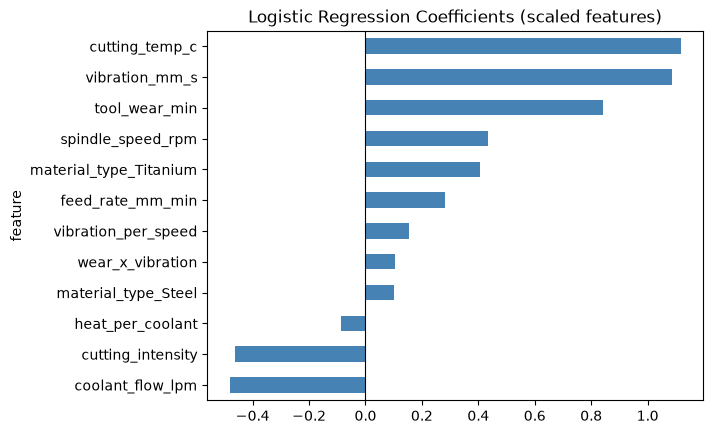

In [3]:
plt.figure(figsize=(8, 5))
coef_df.sort_values("coefficient").plot(
    x="feature", y="coefficient", kind="barh", legend=False, color="steelblue")
plt.title("Logistic Regression Coefficients (scaled features)")
plt.axvline(0, color="black", linewidth=0.8)
plt.savefig("../reports/11_lr_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

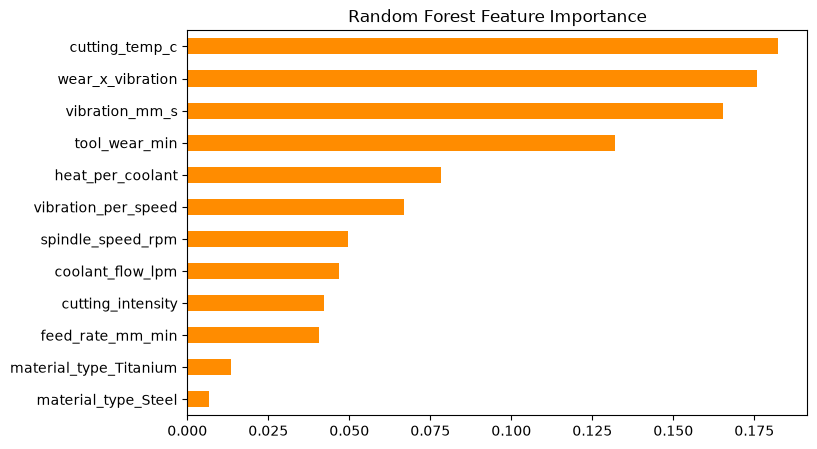

In [4]:
imp = pd.Series(rf.feature_importances_, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 5))
imp.plot(kind="barh", color="darkorange")
plt.title("Random Forest Feature Importance")
plt.savefig("../reports/12_rf_importance.png", dpi=150, bbox_inches="tight")
plt.show()

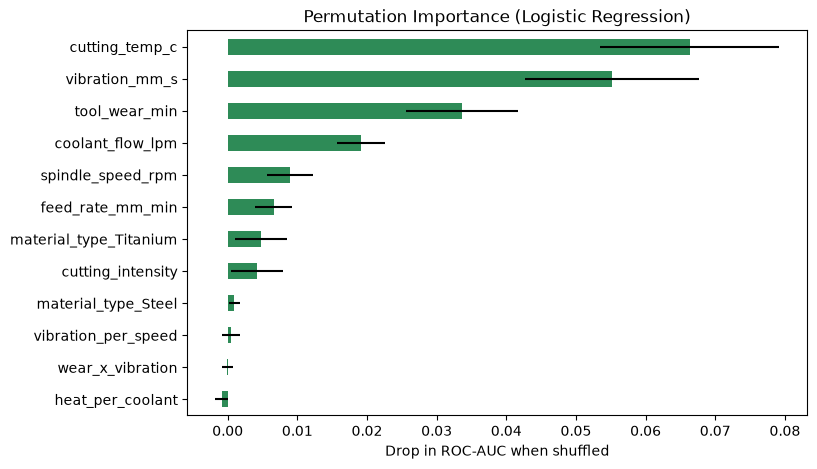

In [5]:
from sklearn.inspection import permutation_importance

result = permutation_importance(lr, X_test, y_test, scoring="roc_auc",
                                n_repeats=20, random_state=42)

perm = pd.Series(result.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 5))
perm.plot(kind="barh", xerr=pd.Series(result.importances_std, index=X_test.columns)[perm.index],
          color="seagreen")
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.title("Permutation Importance (Logistic Regression)")
plt.savefig("../reports/13_permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()